#IMPORTING ALL THE IMPORTANT LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import re
import string

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression

from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,classification_report)



In [ ]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

#LOADING THE DATASET

In [ ]:
df = pd.read_csv("IMDB Dataset.csv")

In [ ]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


In [ ]:
df.shape

(50000, 2)

In [ ]:
df.isnull().sum()

,0
review,0
sentiment,0


In [ ]:
df['sentiment'].value_counts()

,count
sentiment,
positive,25000
negative,25000


#PERFORMING EXPLORATORY DATA ANALYSIS

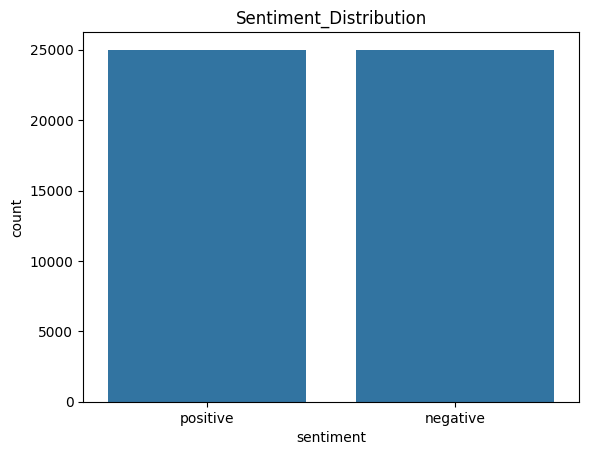

In [ ]:
sns.countplot(data=df, x="sentiment")
plt.title("Sentiment_Distribution")
plt.show()

#TEXT PREPROCESSING

In [ ]:
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

REMOVING STOPWORDS,HTML TAGS,URLS, NUMBERS, PUNCTUATIONS

In [ ]:
def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", "", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Remove numbers
    text = re.sub(r"\d+", "", text)

    # Tokenize
    words = text.split()

    # Remove stopwords and apply stemming
    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    # Join back into a sentence
    return " ".join(words)

In [ ]:
df["clean_review"] = df["review"].apply(clean_text)

In [ ]:
(df["clean_review"] == "").sum()


np.int64(0)

#FEATURE EXTRACTION USING TF-IDF

In [ ]:
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df["clean_review"])

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 4064330 stored elements and shape (50000, 5000)>

In [ ]:
y = df["sentiment"].map({"positive": 1,"negative": 0})

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

VOCABULARY


In [ ]:
print(tfidf.get_feature_names_out()[:20])

['aaron' 'abandon' 'abc' 'abduct' 'abil' 'abl' 'aboard' 'abomin' 'abort'
 'abound' 'abraham' 'abrupt' 'abruptli' 'absenc' 'absent' 'absolut'
 'absorb' 'abstract' 'absurd' 'abund']


#CREATING AND TRAINING LOGISTIC REGRESSION MODEL

In [ ]:
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [ ]:
lr_predictions = lr_model.predict(X_test)

In [ ]:
for i in range(5):
    print("Actual:", y_test.iloc[i])
    print("Predicted:", lr_predictions[i])
    print("-" * 30)


Actual: 1
Predicted: 0
------------------------------
Actual: 1
Predicted: 1
------------------------------
Actual: 0
Predicted: 0
------------------------------
Actual: 1
Predicted: 1
------------------------------
Actual: 0
Predicted: 0
------------------------------


#CREATING AND TRAINING MULTINOMIAL NAIVE BAYES

In [ ]:
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

MultinomialNB()

In [ ]:
nb_predictions = nb_model.predict(X_test)

In [ ]:
for i in range(5):
    print("Actual:", y_test.iloc[i])
    print("Logistic Regression:", lr_predictions[i])
    print("Naive Bayes:", nb_predictions[i])
    print("-" * 40)

Actual: 1
Logistic Regression: 0
Naive Bayes: 0
----------------------------------------
Actual: 1
Logistic Regression: 1
Naive Bayes: 1
----------------------------------------
Actual: 0
Logistic Regression: 0
Naive Bayes: 0
----------------------------------------
Actual: 1
Logistic Regression: 1
Naive Bayes: 1
----------------------------------------
Actual: 0
Logistic Regression: 0
Naive Bayes: 0
----------------------------------------


#MODEL EVALUATION AND CONFUSION MATRIX

1.LOGISTIC REGRESSION

In [ ]:
lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions)
lr_recall = recall_score(y_test, lr_predictions)
lr_f1 = f1_score(y_test, lr_predictions)

In [ ]:
print("Logistic Regression Performance")
print("-" * 35)

print("Accuracy :", lr_accuracy)
print("Precision:", lr_precision)
print("Recall   :", lr_recall)
print("F1 Score :", lr_f1)

Logistic Regression Performance
-----------------------------------
Accuracy : 0.8837
Precision: 0.8732665639445301
Recall   : 0.8997817027187934
F1 Score : 0.886325872348744


2.NAIVE BAYES

In [ ]:
nb_accuracy = accuracy_score(y_test, nb_predictions)
nb_precision = precision_score(y_test, nb_predictions)
nb_recall = recall_score(y_test, nb_predictions)
nb_f1 = f1_score(y_test, nb_predictions)

In [ ]:
print("Naive Bayes Performance")
print("-" * 35)

print("Accuracy :", nb_accuracy)
print("Precision:", nb_precision)
print("Recall   :", nb_recall)
print("F1 Score :", nb_f1)

Naive Bayes Performance
-----------------------------------
Accuracy : 0.8451
Precision: 0.8416209866875489
Recall   : 0.8531454653701132
F1 Score : 0.8473440425741599


#COMPARING BOTH THE MODELS

In [ ]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Logistic Regression": [
        lr_accuracy,
        lr_precision,
        lr_recall,
        lr_f1
    ],
    "Naive Bayes": [
        nb_accuracy,
        nb_precision,
        nb_recall,
        nb_f1
    ]
})

comparison

,Metric,Logistic Regression,Naive Bayes
0,Accuracy,0.883700,0.845100
1,Precision,0.873267,0.841621
2,Recall,0.899782,0.853145
3,F1 Score,0.886326,0.847344


In [ ]:
print(classification_report(y_test, lr_predictions))
print(classification_report(y_test, nb_predictions))

              precision    recall  f1-score   support

           0       0.89      0.87      0.88      4961
           1       0.87      0.90      0.89      5039

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000

              precision    recall  f1-score   support

           0       0.85      0.84      0.84      4961
           1       0.84      0.85      0.85      5039

    accuracy                           0.85     10000
   macro avg       0.85      0.85      0.85     10000
weighted avg       0.85      0.85      0.85     10000



In [ ]:
cm_lr = confusion_matrix(y_test, lr_predictions)
print(cm_lr)

[[4303  658]
 [ 505 4534]]


In [ ]:
cm_nb = confusion_matrix(y_test, nb_predictions)
print(cm_nb)

[[4152  809]
 [ 740 4299]]


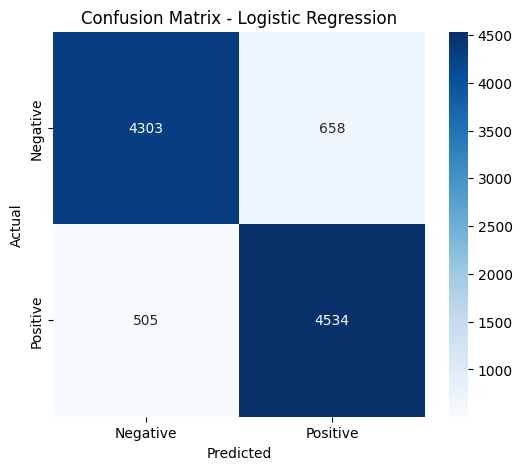

In [ ]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

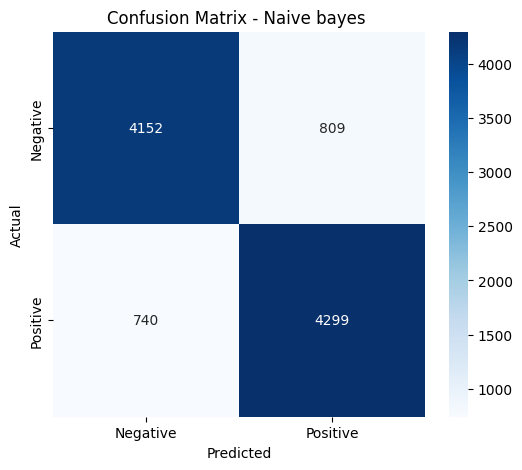

In [40]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Naive bayes ")

plt.show()

FROM THE MODEL EVALUATION WE CONCLUDE THAT WE WILL USE LOGISTIC REGRESSION FOR FURTHER SENTIMENT ANALYSIS

#PREDICTING SENTIMENT FOR THE NEW REVIEWS

In [41]:
def predict_sentiment(review):

    # Step 1: Clean the review
    cleaned_review = clean_text(review)

    # Step 2: Convert to TF-IDF features
    review_vector = tfidf.transform([cleaned_review])

    # Step 3: Predict sentiment
    prediction = lr_model.predict(review_vector)[0]

    # Step 4: Return label
    if prediction == 1:
        return "Positive "
    else:
        return "Negative "

In [43]:
review = "This movie was absolutely not so good. It was boring."
print(predict_sentiment(review))

Negative 


In [44]:
review = "One of the best movies I have ever watched."
print(predict_sentiment(review))

Positive 


In [45]:
reviews = [
    "Amazing movie with brilliant acting.",
    "Worst film I have ever seen.",
    "The story was interesting but a little slow.",
    "Absolutely loved the soundtrack and performances.",
    "Not worth watching."
]

for review in reviews:
    print("Review:", review)
    print("Prediction:", predict_sentiment(review))
    print("-" * 50)

Review: Amazing movie with brilliant acting.
Prediction: Positive 
--------------------------------------------------
Review: Worst film I have ever seen.
Prediction: Negative 
--------------------------------------------------
Review: The story was interesting but a little slow.
Prediction: Negative 
--------------------------------------------------
Review: Absolutely loved the soundtrack and performances.
Prediction: Positive 
--------------------------------------------------
Review: Not worth watching.
Prediction: Positive 
--------------------------------------------------


In [46]:
import joblib

joblib.dump(lr_model, "sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

In [47]:
lr_model = joblib.load("sentiment_model.pkl")
tfidf = joblib.load("tfidf_vectorizer.pkl")